# NETFLIX — DATA EXPLORATION & VISUALISATION
 (Name: Akhil Deshmukh  | Email: akdesh156@gmail.com)
## Business Case Study

### Objective
Analyse Netflix's content catalogue to identify patterns in content type, release trends, content additions, creators, countries and content characteristics.

### Key Business Questions
1. How has the number of movies released per year changed over the last 20–30 years?
2. How does Netflix's TV Show catalogue compare with Movies?
3. What is the best historical month for Netflix to add TV Shows?
4. Which actors and directors are most frequently represented across Movies and TV Shows?
5. Has Netflix increased its focus on TV Shows in recent years?
6. What type of content is available across different countries?

### Business Perspective
The objective is not only to describe the Netflix catalogue, but to identify measurable patterns that can support content planning, market prioritisation and portfolio decisions.

# 1. Defining Problem Statement and Analysing Basic Metrics

Netflix has a large and diverse content catalogue containing Movies and TV Shows from multiple countries, genres, creators and release periods.

The business objective is to understand how this catalogue is structured and identify patterns that can help Netflix evaluate content mix, geographic coverage, creator representation and historical content-addition behaviour and recommend the type of Shows/Movies to Produce and how to grow business in different countries.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

### Insight

These libraries provide the tools required for data loading, data manipulation, statistical analysis and visualisation. The display and plotting settings improve how tables and charts are presented in the notebook.

In [ ]:
url = "https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/000/940/original/netflix.csv"
df = pd.read_csv(url)
display(df.head())

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


### Insight

The dataset contains catalogue-level information on content type, release year, country, cast, director, genre, rating and duration. These fields support analysis of Netflix's portfolio structure, geographic and creator representation.

In [ ]:
print("Dataset shape:", df.shape)


Dataset shape: (8807, 12)


### Insight

The dataset contains **8,807 rows and 12 attributes**, providing sufficient records to compare content formats, release periods, countries, creators and content characteristics.

# 2. Dataset Structure, Data Types, Missing Values & Statistical Summary

Before analysing business patterns, the dataset is checked for structure, data types, missing values, duplicates and numerical distributions.

In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Total catalogue records:", len(df))
print("Movies:", (df["type"] == "Movie").sum())
print("TV Shows:", (df["type"] == "TV Show").sum())
print("Unique titles:", df["title"].nunique())

Rows: 8807
Columns: 12
Total catalogue records: 8807
Movies: 6131
TV Shows: 2676
Unique titles: 8807


### Insight

Netflix has **8,807 catalogue records**, including **6,131 Movies and 2,676 TV Shows**. Movies therefore represent approximately **69.6%** of the catalogue, making Movies the larger portfolio segment. TV expansion should therefore be viewed as growth of a smaller segment rather than a replacement of the core Movie catalogue.

In [ ]:
display(df.dtypes.to_frame("Data Type"))

,Data Type
show_id,object
type,object
title,object
director,object
cast,object
country,object
date_added,object
release_year,int64
rating,object
duration,object


### Insight

Most fields are categorical or text-based, while `release_year` is numeric and `date_added` requires date conversion. Converting `date_added` is essential because the TV addition analysis depends on accurate year and month values.

In [ ]:
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month
df["month_name"] = df["date_added"].dt.month_name()
df["month_num"] = df["date_added"].dt.month

### Insight

Date conversion enables Netflix's historical content-addition behaviour to be measured by month and year. Importantly, `date_added` represents when content entered Netflix's catalogue, not when the content was originally released.

In [ ]:
df["type"] = df["type"].astype("category")
df["rating"] = df["rating"].astype("category")
display(df.dtypes)

,0
show_id,object
type,category
title,object
director,object
cast,object
country,object
date_added,datetime64[ns]
release_year,int64
rating,category
duration,object


### Insight

`type` and `rating` contain a limited number of repeated business categories, making them appropriate for categorical comparisons such as portfolio mix and rating-level runtime analysis.

In [ ]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_table = pd.DataFrame({"Missing Values": missing, "Missing %": missing_pct})
display(missing_table[missing_table["Missing Values"] > 0])

,Missing Values,Missing %
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,98,1.11
year_added,98,1.11
month_added,98,1.11
month_name,98,1.11
month_num,98,1.11
rating,4,0.05
duration,3,0.03


### Insight

Missing information is concentrated in **director, cast and country**, which directly affects creator and geographic analysis. Director data is missing for roughly **30%** of records, so creator-level findings should be treated as representation within the available metadata rather than complete catalogue coverage.

In [ ]:
duplicate_count = df.duplicated().sum()
print("Duplicate records:", duplicate_count)

Duplicate records: 0


### Insight

The dataset contains **0 duplicate records**, so catalogue counts are not artificially inflated by repeated rows.

In [ ]:
if duplicate_count > 0:
    df = df.drop_duplicates().copy()
print("Dataset shape after duplicate treatment:", df.shape)

Dataset shape after duplicate treatment: (8807, 16)


### Insight

Because no duplicates are present, duplicate treatment does not change the catalogue size. Subsequent content-mix and trend calculations therefore do not require adjustment for exact duplicate records.

In [ ]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
show_id,8807,8807,s8807,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8807,2,Movie,6131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8807,8807,Zubaan,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,6173,4528,Rajiv Chilaka,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7982,7692,David Attenborough,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7976,748,United States,2818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8709,NaN,NaN,NaN,2019-05-23 01:45:29.452290816,2008-01-01 00:00:00,2018-04-20 00:00:00,2019-07-12 00:00:00,2020-08-26 00:00:00,2021-09-25 00:00:00,NaN
release_year,8807.0,NaN,NaN,NaN,2014.180198,1925.0,2013.0,2017.0,2019.0,2021.0,8.819312
rating,8803,17,TV-MA,3207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8804,220,1 Season,1793,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Insight

The statistical summary establishes the numerical range and central tendency needed for later business analysis. Release year, Movie duration and TV Show season count are the key numerical attributes because they describe content freshness and format characteristics.

# 3. Non-Graphical Analysis

Non-graphical analysis quantifies the catalogue before visual interpretation, focusing on unique values, content-type proportions, ratings and release-year concentration.

In [ ]:
unique_values = df.nunique().sort_values(ascending=False); display(unique_values.to_frame("Unique Values"))

,Unique Values
show_id,8807
title,8807
description,8775
cast,7692
director,4528
date_added,1699
country,748
listed_in,514
duration,220
release_year,74


### Insight

Titles, descriptions and creator fields are highly granular, while `type` and `rating` contain relatively few categories. Portfolio decisions should therefore focus on dimensions that can be compared consistently across large portions of the catalogue.

In [ ]:
type_counts = df["type"].value_counts()
type_share = (type_counts / len(df) * 100).round(2)
content_type_summary = pd.DataFrame({"Count": type_counts, "Share %": type_share})
display(content_type_summary)

,Count,Share %
type,,
Movie,6131,69.62
TV Show,2676,30.38


### Insight

Movies contribute **6,131 titles (69.6%)**, compared with **2,676 TV Shows (30.4%)**. The Movie catalogue is approximately **2.3 times larger** than the TV catalogue, confirming that Movies remain Netflix's dominant accumulated content format.

In [ ]:
rating_counts = df["rating"].value_counts(dropna=False); display(rating_counts.to_frame("Count"))

,Count
rating,
TV-MA,3207
TV-14,2160
TV-PG,863
R,799
PG-13,490
TV-Y7,334
TV-Y,307
PG,287
TV-G,220


### Insight

The concentration of titles across a limited set of ratings indicates that Netflix's catalogue is structured around a relatively small number of audience-rating categories. This makes rating mix useful for evaluating audience-segment coverage.

In [ ]:
release_year_counts = df["release_year"].value_counts().sort_index(); display(release_year_counts.tail(20).to_frame("Titles"))

,Titles
release_year,
2002,51
2003,61
2004,64
2005,80
2006,96
2007,88
2008,136
2009,152
2010,194


### Insight

Recent release years contain a substantial concentration of catalogue titles, indicating that Netflix's library is weighted toward newer content rather than being evenly distributed across its full historical range. This supports a closer analysis of release trends.

# 4. Visual Analysis and Mandatory Business Questions

The analysis uses different chart types according to the business question: line charts for trends, histograms for distributions, bars for categorical comparisons and composition, heatmaps for many-to-many matrices, and scatterplots for numerical relationships.

## 4.1 Data Pre-processing and Unnesting

Country, cast, director and genre contain multiple values in single rows. They are separated into individual observations so each business dimension can be measured independently.

In [ ]:
df_country = df.dropna(subset=["country"]).copy()
df_country["country"] = df_country["country"].str.split(",")
df_country = df_country.explode("country").reset_index(drop=True)
df_country["country"] = df_country["country"].str.strip()
display(df_country[["title", "country", "type"]].head())

,title,country,type
0,Dick Johnson Is Dead,United States,Movie
1,Blood & Water,South Africa,TV Show
2,Kota Factory,India,TV Show
3,Sankofa,United States,Movie
4,Sankofa,Ghana,Movie


### Insight

Country unnesting allows multi-country titles to contribute to each country represented in their metadata, giving a more accurate view of Netflix's geographic catalogue footprint.

In [ ]:
df_cast = df.dropna(subset=["cast"]).copy()
df_cast["cast"] = df_cast["cast"].str.split(",")
df_cast = df_cast.explode("cast").reset_index(drop=True)
df_cast["cast"] = df_cast["cast"].str.strip()
display(df_cast[["title", "cast", "type"]].head())

,title,cast,type
0,Blood & Water,Ama Qamata,TV Show
1,Blood & Water,Khosi Ngema,TV Show
2,Blood & Water,Gail Mabalane,TV Show
3,Blood & Water,Thabang Molaba,TV Show
4,Blood & Water,Dillon Windvogel,TV Show


### Insight

Actor unnesting makes creator representation measurable at individual-actor level, allowing Movie and TV Show representation to be compared without treating an entire cast list as one category.

In [ ]:
df_director = df.dropna(subset=["director"]).copy()
df_director["director"] = df_director["director"].str.split(",")
df_director = df_director.explode("director").reset_index(drop=True)
df_director["director"] = df_director["director"].str.strip()
display(df_director[["title", "director", "type"]].head())

,title,director,type
0,Dick Johnson Is Dead,Kirsten Johnson,Movie
1,Ganglands,Julien Leclercq,TV Show
2,Midnight Mass,Mike Flanagan,TV Show
3,My Little Pony: A New Generation,Robert Cullen,Movie
4,My Little Pony: A New Generation,José Luis Ucha,Movie


### Insight

Director unnesting enables repeated creator representation to be quantified and separated by content format. This helps identify creators with stronger Movie or TV Show catalogue presence.

In [ ]:
df_genre = df.dropna(subset=["listed_in"]).copy()
df_genre["genre"] = df_genre["listed_in"].str.split(",")
df_genre = df_genre.explode("genre").reset_index(drop=True)
df_genre["genre"] = df_genre["genre"].str.strip()
display(df_genre[["title", "genre", "type"]].head())

,title,genre,type
0,Dick Johnson Is Dead,Documentaries,Movie
1,Blood & Water,International TV Shows,TV Show
2,Blood & Water,TV Dramas,TV Show
3,Blood & Water,TV Mysteries,TV Show
4,Ganglands,Crime TV Shows,TV Show


### Insight

Genre unnesting preserves every genre attached to a title, preventing multi-genre titles from being reduced to a single category and allowing catalogue concentration by genre to be evaluated accurately.

In [ ]:
df["duration_value"] = pd.to_numeric(df["duration"].str.extract(r"(\d+)")[0], errors="coerce")
df["movie_duration"] = df["duration_value"].where(df["type"].eq("Movie"))
df["tv_seasons"] = df["duration_value"].where(df["type"].eq("TV Show"))
display(df[["type", "duration", "movie_duration", "tv_seasons"]].head())

,type,duration,movie_duration,tv_seasons
0,Movie,90 min,90.0,NaN
1,TV Show,2 Seasons,NaN,2.0
2,TV Show,1 Season,NaN,1.0
3,TV Show,1 Season,NaN,1.0
4,TV Show,2 Seasons,NaN,2.0


### Insight

Movie duration is measured in minutes, whereas TV Show duration is measured in seasons. Keeping these measures separate avoids an invalid minutes-versus-seasons comparison and preserves the correct business meaning of each format.

## Q1 — How has the number of Movies released per year changed over the last 20–30 years?

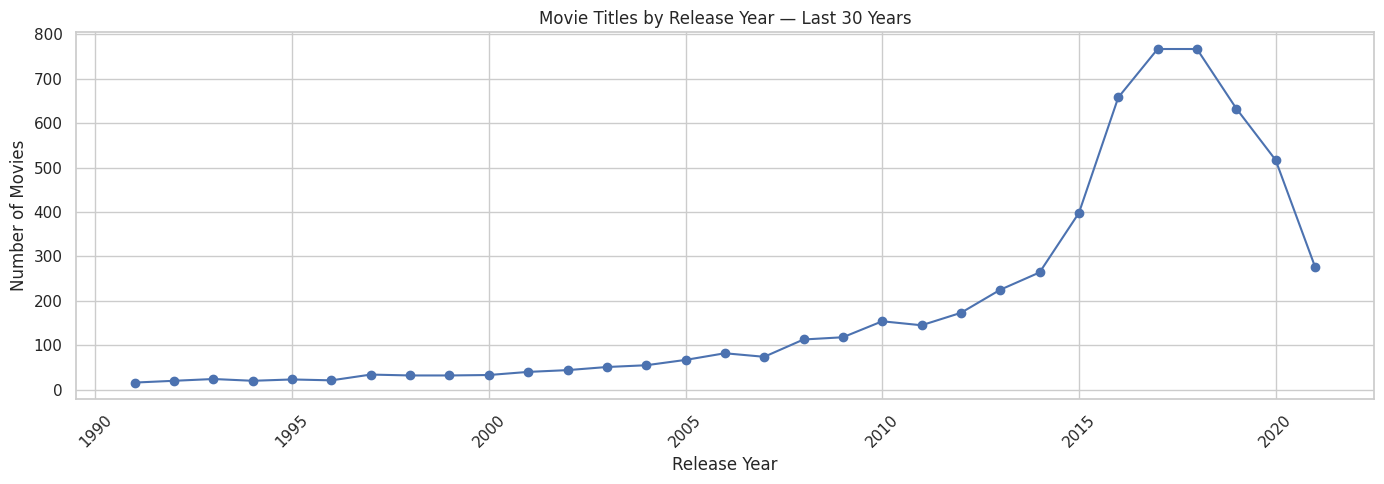

Peak movie release year in the catalogue: 2017 (767 titles)
First 5 years total: 103
Last 5 years total: 2961
Change from first 5 to last 5 years: 2774.76%


In [ ]:
max_release_year = int(df["release_year"].max())
start_year = max_release_year - 30
movies_by_year = df[(df["type"].eq("Movie")) & (df["release_year"].between(start_year, max_release_year))].groupby("release_year").size()
movies_by_year = movies_by_year.reindex(range(start_year, max_release_year + 1), fill_value=0)
peak_movie_year = int(movies_by_year.idxmax())
peak_movie_count = int(movies_by_year.max())
early_years = movies_by_year.index[:5]
late_years = movies_by_year.index[-5:]
early_movie_count = int(movies_by_year.loc[early_years].sum())
late_movie_count = int(movies_by_year.loc[late_years].sum())
change_pct = ((late_movie_count - early_movie_count) / early_movie_count * 100) if early_movie_count else np.nan

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(movies_by_year.index, movies_by_year.values, marker="o")
ax.set_title("Movie Titles by Release Year — Last 30 Years")
ax.set_xlabel("Release Year")
ax.set_ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(f"Peak movie release year in the catalogue: {peak_movie_year} ({peak_movie_count} titles)")
print(f"First 5 years total: {early_movie_count}")
print(f"Last 5 years total: {late_movie_count}")
print(f"Change from first 5 to last 5 years: {change_pct:.2f}%")

### Insight

**Movie representation increased sharply across the 30-year window**. The first 5 years contained 103 Movies, compared with 2,961 Movies in the last 5 years, an increase of approximately 2,775%. **The highest representation was in 2017 with 767 Movies**. This indicates that Netflix's catalogue is strongly concentrated toward newer Movie releases.

## Q2 — Comparison of TV Shows vs Movies

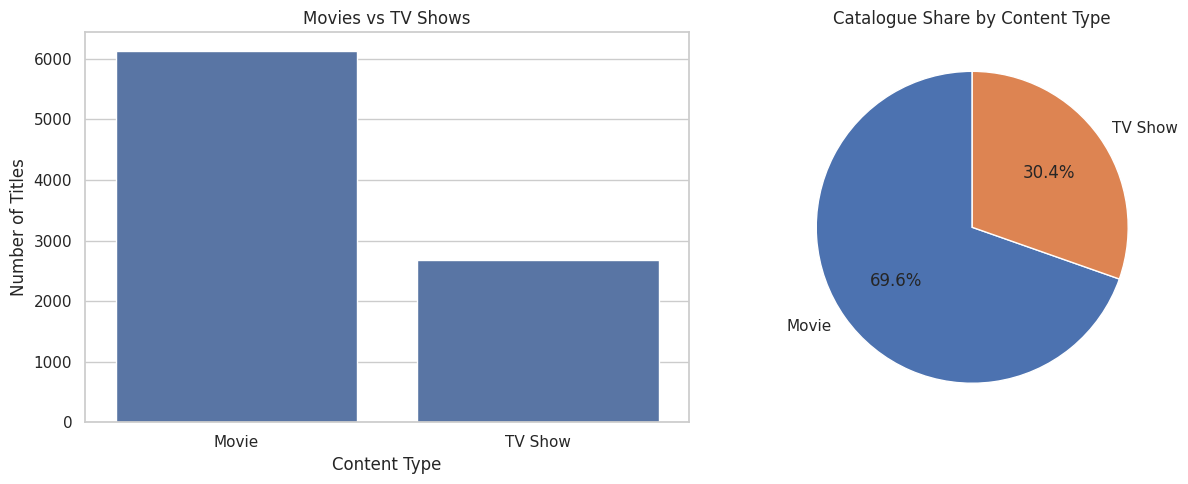

Movies: 6131 (69.62%)
TV Shows: 2676 (30.38%)
Movie-to-TV ratio: 2.29:1


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(data=df, x="type", ax=axes[0])
axes[0].set_title("Movies vs TV Shows")
axes[0].set_xlabel("Content Type")
axes[0].set_ylabel("Number of Titles")
type_share.plot(kind="pie", autopct="%1.1f%%", startangle=90, ax=axes[1])
axes[1].set_title("Catalogue Share by Content Type")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

movie_count = int(type_counts.get("Movie", 0))
tv_count = int(type_counts.get("TV Show", 0))
movie_share = movie_count / len(df) * 100
tv_share = tv_count / len(df) * 100
movie_tv_ratio = movie_count / tv_count

print(f"Movies: {movie_count} ({movie_share:.2f}%)")
print(f"TV Shows: {tv_count} ({tv_share:.2f}%)")
print(f"Movie-to-TV ratio: {movie_tv_ratio:.2f}:1")

### Insight

Movies account for **69.6%** of the catalogue versus **30.4%** for TV Shows. With roughly **2.3 Movies for every TV Show**, Netflix remains structurally Movie-heavy. TV Show growth would therefore represent meaningful portfolio expansion rather than the current dominant format.

## Q3 — What is the best time to launch a TV show?

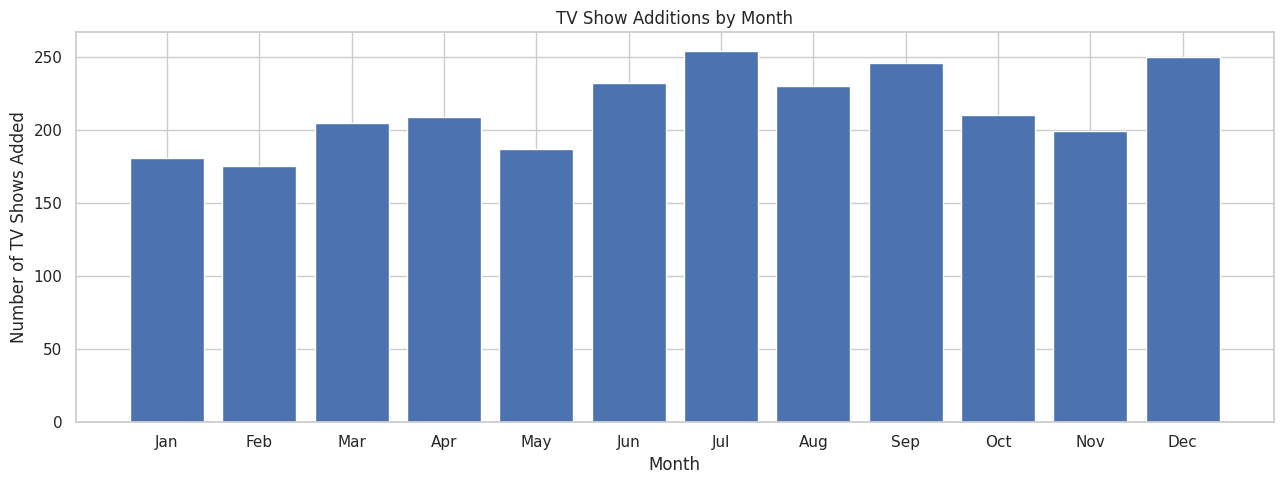

Highest TV Show addition month: July
TV Shows added in that month: 254
Share of dated TV Show additions: 9.85%


In [ ]:
tv_monthly = df[(df["type"].eq("TV Show")) & df["month_num"].notna()].groupby("month_num").size().reindex(range(1, 13), fill_value=0)
month_labels = pd.to_datetime(pd.Series(range(1, 13)), format="%m").dt.month_name().str[:3]
best_month_num = int(tv_monthly.idxmax())
best_month_count = int(tv_monthly.max())
best_month_name = pd.Timestamp(2000, best_month_num, 1).strftime("%B")
total_tv_with_date = int(tv_monthly.sum())
best_month_share = best_month_count / total_tv_with_date * 100

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(month_labels, tv_monthly.values)
ax.set_title("TV Show Additions by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Number of TV Shows Added")
plt.tight_layout()
plt.show()

print(f"Highest TV Show addition month: {best_month_name}")
print(f"TV Shows added in that month: {best_month_count}")
print(f"Share of dated TV Show additions: {best_month_share:.2f}%")

### Insight

**July** month has the highest historical TV Show addition volume, with **254** titles, representing **9.85%** of dated TV Show additions. This makes the month a useful historical planning benchmark. However, it cannot be called the objectively best launch month because the dataset does not contain viewing, engagement or revenue outcomes.

## Q4 — Analysis of actors/directors of different types of shows/movies

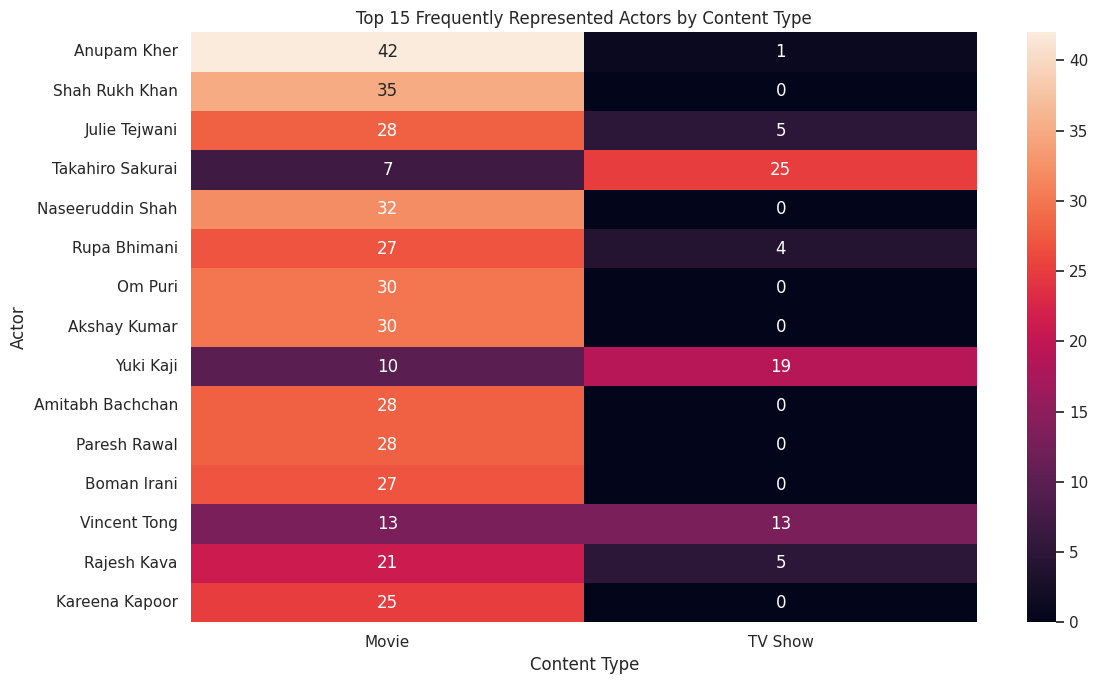

Most frequently represented actor: Anupam Kher
Total titles: 43
Movies: 42
TV Shows: 1


In [ ]:
actor_type = pd.crosstab(df_cast["cast"], df_cast["type"])
for content_type in ["Movie", "TV Show"]:
    if content_type not in actor_type.columns:
        actor_type[content_type] = 0
actor_type["Total"] = actor_type[["Movie", "TV Show"]].sum(axis=1)
top_actors = actor_type.sort_values("Total", ascending=False).head(15)

plt.figure(figsize=(12, 7))
sns.heatmap(top_actors[["Movie", "TV Show"]], annot=True, fmt="g")
plt.title("Top 15 Frequently Represented Actors by Content Type")
plt.xlabel("Content Type")
plt.ylabel("Actor")
plt.tight_layout()
plt.show()

top_actor = top_actors.index[0]
print(f"Most frequently represented actor: {top_actor}")
print(f"Total titles: {int(top_actors.loc[top_actor, 'Total'])}")
print(f"Movies: {int(top_actors.loc[top_actor, 'Movie'])}")
print(f"TV Shows: {int(top_actors.loc[top_actor, 'TV Show'])}")

### Insight

**Anupam Kher** is the most frequently represented actor in the catalogue with **43 titles, including 42 Movies and 1 TV Show**. For TV Shows, **Takahiro Sakurai** has the highest representation with **25 titles**. This shows that the actors most frequently represented in Movies and TV Shows are different.

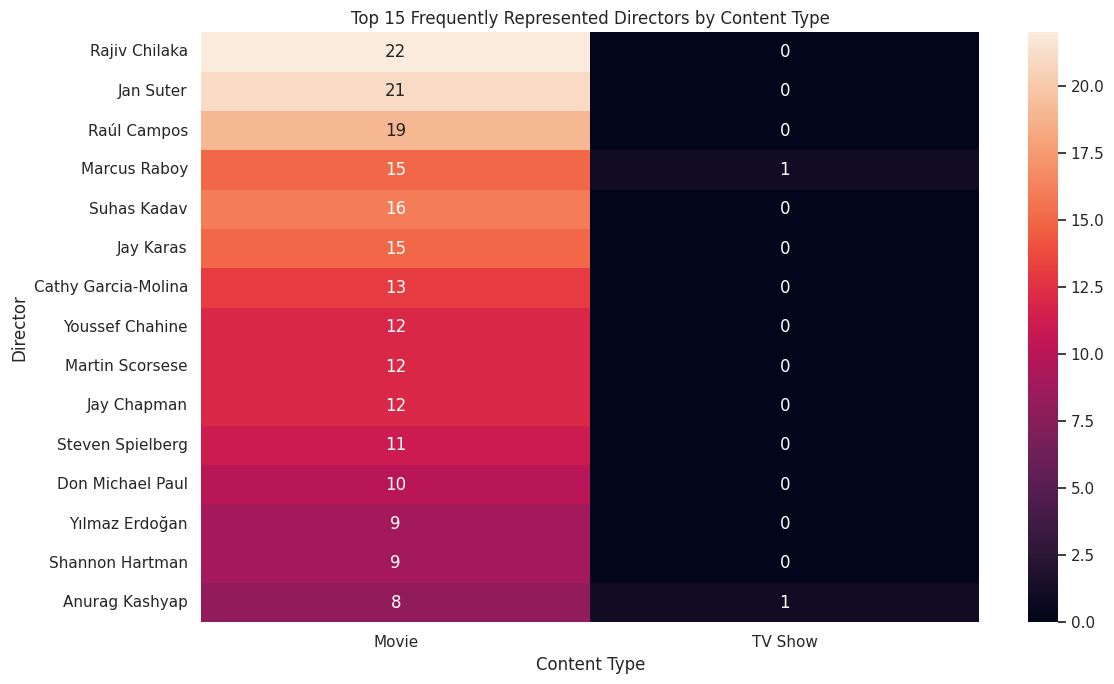

Most frequently represented director: Rajiv Chilaka
Total titles: 22
Movies: 22
TV Shows: 0


In [ ]:
director_type = pd.crosstab(df_director["director"], df_director["type"])
for content_type in ["Movie", "TV Show"]:
    if content_type not in director_type.columns:
        director_type[content_type] = 0
director_type["Total"] = director_type[["Movie", "TV Show"]].sum(axis=1)
top_directors = director_type.sort_values("Total", ascending=False).head(15)

plt.figure(figsize=(12, 7))
sns.heatmap(top_directors[["Movie", "TV Show"]], annot=True, fmt="g")
plt.title("Top 15 Frequently Represented Directors by Content Type")
plt.xlabel("Content Type")
plt.ylabel("Director")
plt.tight_layout()
plt.show()

top_director = top_directors.index[0]
print(f"Most frequently represented director: {top_director}")
print(f"Total titles: {int(top_directors.loc[top_director, 'Total'])}")
print(f"Movies: {int(top_directors.loc[top_director, 'Movie'])}")
print(f"TV Shows: {int(top_directors.loc[top_director, 'TV Show'])}")

### Insight

**Rajiv Chilaka** is the most frequently represented director with **22 titles**, all of which are Movies. In the displayed top directors, TV Show representation is very limited, with directors appearing in **0 or 1 TV Show**. Therefore, the directors shown are much more frequently represented through Movies than TV Shows.


## Q5 — Does Netflix has more focus on TV Shows than movies in recent years

/tmp/ipykernel_40495/1240531394.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  yearly_content = df.dropna(subset=["year_added"]).groupby(["year_added", "type"]).size().unstack(fill_value=0)


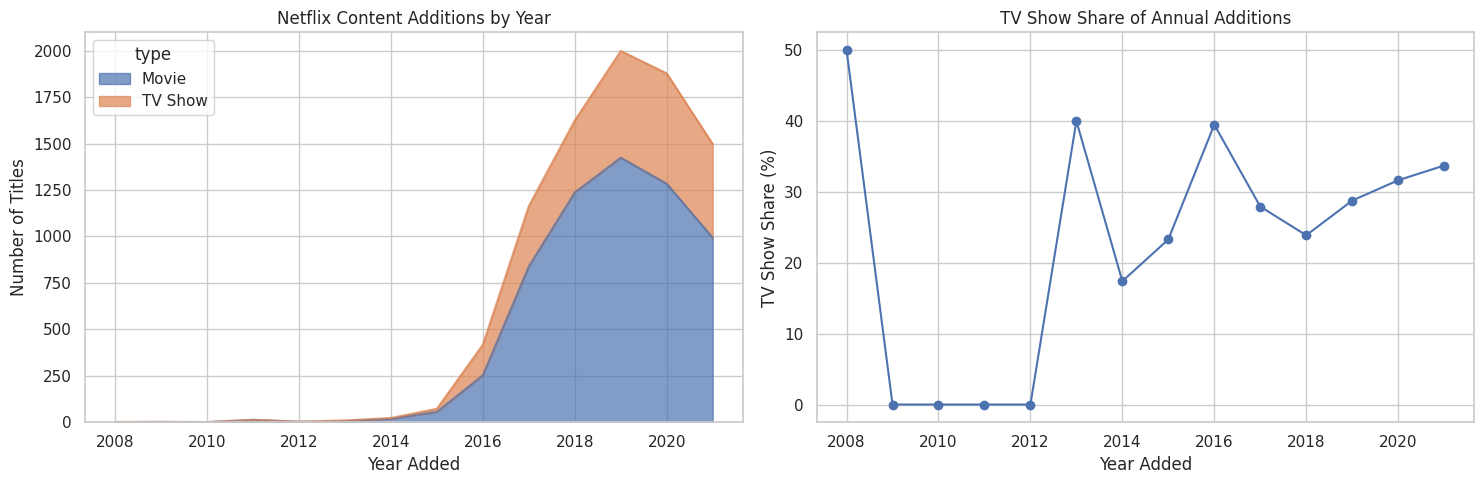

First 5 available years TV Show share: 4.76%
Last 5 available years TV Show share: 29.24%
Change in TV Show share: 24.48 percentage points


In [ ]:
yearly_content = df.dropna(subset=["year_added"]).groupby(["year_added", "type"]).size().unstack(fill_value=0)
for content_type in ["Movie", "TV Show"]:
    if content_type not in yearly_content.columns:
        yearly_content[content_type] = 0
yearly_content["Total"] = yearly_content[["Movie", "TV Show"]].sum(axis=1)
yearly_content["TV_Show_Share"] = yearly_content["TV Show"] / yearly_content["Total"] * 100

years = yearly_content.index.sort_values()
first_period = years[:min(5, len(years))]
last_period = years[-min(5, len(years)):]
early_tv = int(yearly_content.loc[first_period, "TV Show"].sum())
early_total = int(yearly_content.loc[first_period, "Total"].sum())
recent_tv = int(yearly_content.loc[last_period, "TV Show"].sum())
recent_total = int(yearly_content.loc[last_period, "Total"].sum())
early_share = early_tv / early_total * 100
recent_share = recent_tv / recent_total * 100
share_change = recent_share - early_share

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
yearly_content[["Movie", "TV Show"]].plot.area(ax=axes[0], alpha=0.7)
axes[0].set_title("Netflix Content Additions by Year")
axes[0].set_xlabel("Year Added")
axes[0].set_ylabel("Number of Titles")
axes[1].plot(yearly_content.index, yearly_content["TV_Show_Share"], marker="o")
axes[1].set_title("TV Show Share of Annual Additions")
axes[1].set_xlabel("Year Added")
axes[1].set_ylabel("TV Show Share (%)")
plt.tight_layout()
plt.show()

print(f"First 5 available years TV Show share: {early_share:.2f}%")
print(f"Last 5 available years TV Show share: {recent_share:.2f}%")
print(f"Change in TV Show share: {share_change:.2f} percentage points")

### Insight

**Yes, Netflix has shown a stronger focus on TV Shows in recent years**. TV Shows accounted for only 4.76% of additions in the first 5 available years, but this increased to 29.24% in the last 5 available years, a rise of 24.48 percentage points. The graph therefore shows a clear shift toward adding more TV Shows in the later years of the dataset, although Movies still account for the larger share of annual additions.

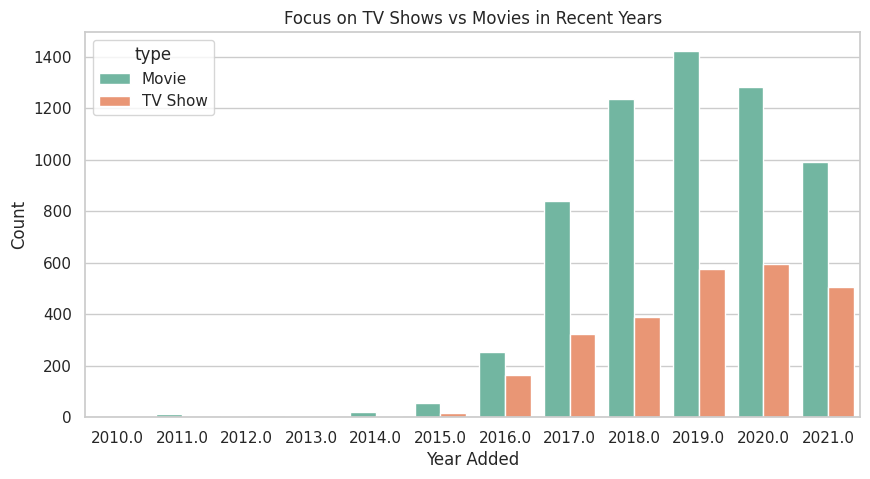

In [ ]:
df['year_added'] = df['date_added'].dt.year

# Q: Does Netflix have more focus on TV Shows than movies in recent years?
plt.figure(figsize=(10, 5))
sns.countplot(data=df[df['year_added'] >= 2010], x='year_added', hue='type', palette='Set2')
plt.title('Focus on TV Shows vs Movies in Recent Years')
plt.xlabel('Year Added')
plt.ylabel('Count')
plt.show()

**Insight:** Movies remain higher in annual additions across the recent period, while TV Show additions have also grown. The pattern indicates continued Movie strength alongside increasing TV Show representation rather than a complete shift toward TV Shows.

## Q6 — Understanding what content is available in different countries

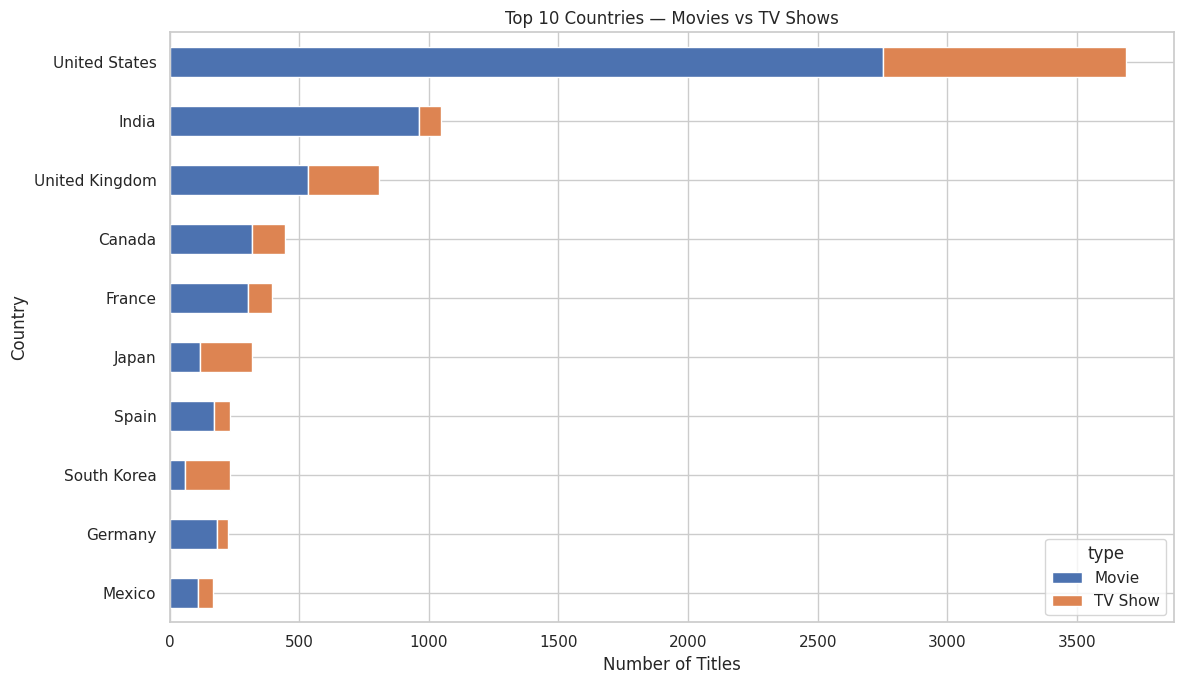

Largest country catalogue representation: United States
Titles associated with that country: 3690


In [ ]:
top_10_countries = df_country["country"].value_counts().head(10)
top_country_names = top_10_countries.index.tolist()
top_country_data = df_country[df_country["country"].isin(top_country_names)].copy()

country_content_type = pd.crosstab(index=top_country_data["country"], columns=top_country_data["type"])
for content_type in ["Movie", "TV Show"]:
    if content_type not in country_content_type.columns:
        country_content_type[content_type] = 0
country_content_type["Total"] = country_content_type[["Movie", "TV Show"]].sum(axis=1)
country_content_type = country_content_type.sort_values("Total", ascending=True)

country_content_type[["Movie", "TV Show"]].plot(kind="barh", stacked=True, figsize=(12, 7))
plt.title("Top 10 Countries — Movies vs TV Shows")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

largest_country = country_content_type["Total"].idxmax()
print(f"Largest country catalogue representation: {largest_country}")
print(f"Titles associated with that country: {int(country_content_type.loc[largest_country, 'Total'])}")

### Insight
The **United States** has the largest catalogue representation among the top countries, with **3,690 associated titles**. The Movie/TV mix also varies across countries, showing that Netflix's catalogue composition is not the same in every market.


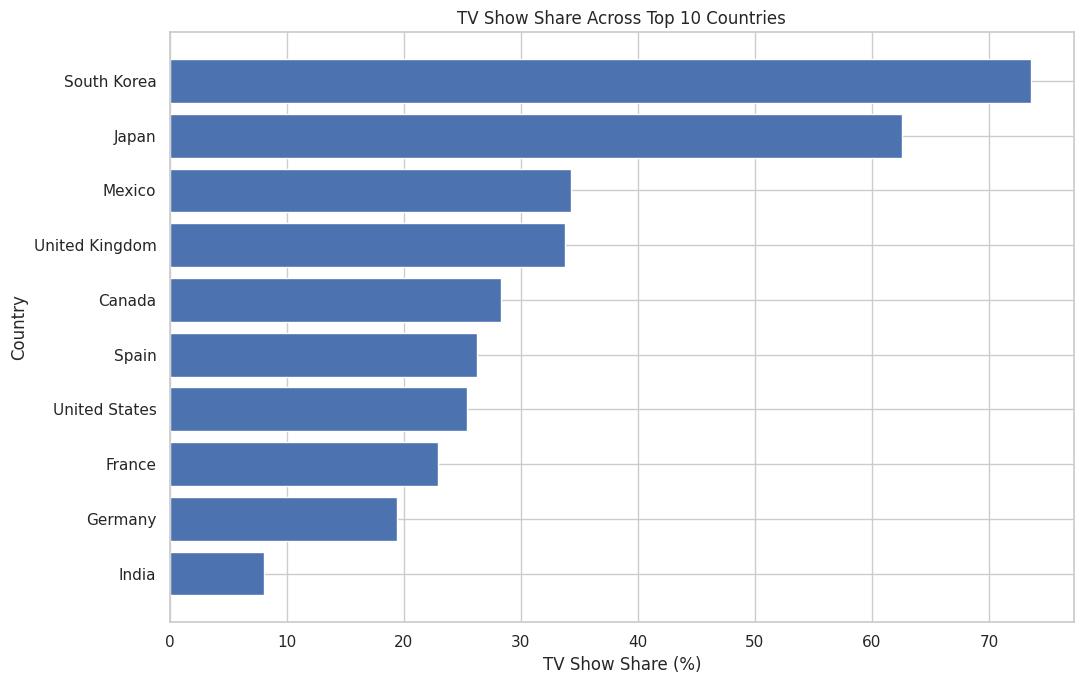

Highest TV Show share: South Korea (73.59%)
Lowest TV Show share: India (8.03%)
Difference between highest and lowest TV shares: 65.56 percentage points


In [ ]:
country_mix = country_content_type.copy()
country_mix["TV_Show_Share"] = country_mix["TV Show"] / country_mix["Total"] * 100
country_mix = country_mix.sort_values("TV_Show_Share", ascending=True)

plt.figure(figsize=(11, 7))
plt.barh(country_mix.index, country_mix["TV_Show_Share"])
plt.xlabel("TV Show Share (%)")
plt.ylabel("Country")
plt.title("TV Show Share Across Top 10 Countries")
plt.tight_layout()
plt.show()

highest_tv_country = country_mix["TV_Show_Share"].idxmax()
highest_tv_share = country_mix["TV_Show_Share"].max()
lowest_tv_country = country_mix["TV_Show_Share"].idxmin()
lowest_tv_share = country_mix["TV_Show_Share"].min()
share_gap = highest_tv_share - lowest_tv_share

print(f"Highest TV Show share: {highest_tv_country} ({highest_tv_share:.2f}%)")
print(f"Lowest TV Show share: {lowest_tv_country} ({lowest_tv_share:.2f}%)")
print(f"Difference between highest and lowest TV shares: {share_gap:.2f} percentage points")

### Insight
The **TV Show share varies substantially across the major countries**, from 8.03% in India to 73.59% in South Korea, a difference of 65.56 percentage points. This shows that the Movie/TV mix differs considerably by market.


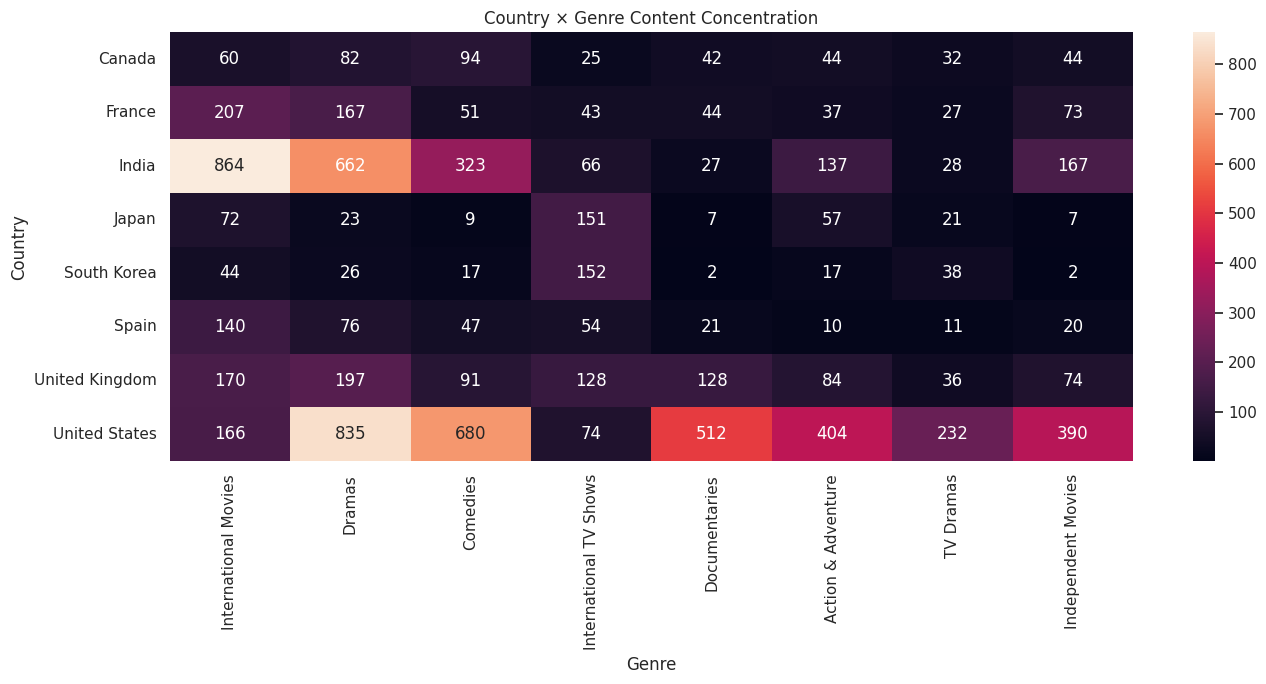

In [ ]:
df_country_genre = df_country.merge(
    df_genre[["show_id", "genre"]].drop_duplicates(),
    on="show_id",
    how="inner"
)
top_genres = df_genre["genre"].value_counts().head(8).index
top_countries_for_genre = df_country["country"].value_counts().head(8).index

country_genre = pd.crosstab(df_country_genre["country"], df_country_genre["genre"])
country_genre = country_genre.loc[country_genre.index.intersection(top_countries_for_genre)]
country_genre = country_genre[top_genres.intersection(country_genre.columns)]

plt.figure(figsize=(14, 7))
sns.heatmap(country_genre, annot=True, fmt="g")
plt.title("Country × Genre Content Concentration")
plt.xlabel("Genre")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

### Insight

The country-by-genre concentrations identify where Netflix already has stronger catalogue coverage in particular genres. Large counts indicate existing catalogue strength, while lower counts identify potential gaps that should be evaluated against local customer demand before being treated as investment opportunities.

## 4.2 Univariate Analysis

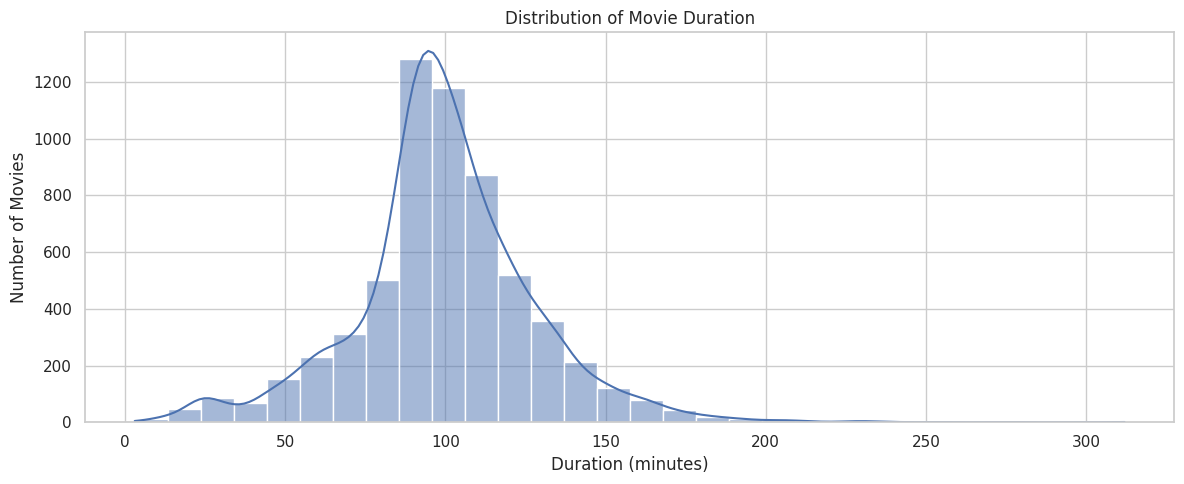

Mean movie duration: 99.58 minutes
Median movie duration: 98.00 minutes
25th percentile: 87.00 minutes
75th percentile: 114.00 minutes


In [ ]:
duration_series = df["movie_duration"].dropna()
plt.figure(figsize=(12, 5))
sns.histplot(duration_series, bins=30, kde=True)
plt.title("Distribution of Movie Duration")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

print(f"Mean movie duration: {duration_series.mean():.2f} minutes")
print(f"Median movie duration: {duration_series.median():.2f} minutes")
print(f"25th percentile: {duration_series.quantile(0.25):.2f} minutes")
print(f"75th percentile: {duration_series.quantile(0.75):.2f} minutes")

### **Note on Univariate Distribution Plot:**

Here used **sns.histplot()** with kde=True  as the current supported alternative for distribution analysis as sns.distplot() is deprecated in recent versions of Seaborn. This provides the same histogram-based distribution view with a KDE curve while maintaining compatibility with the current Seaborn version.

### Insight

The average Movie duration is 99.58 minutes, while the median is 98.00 minutes. Since the mean is slightly higher than the median, longer Movies have a small upward effect on the average. The middle 50% of Movies fall between 87 and 114 minutes, showing a relatively concentrated typical runtime range.


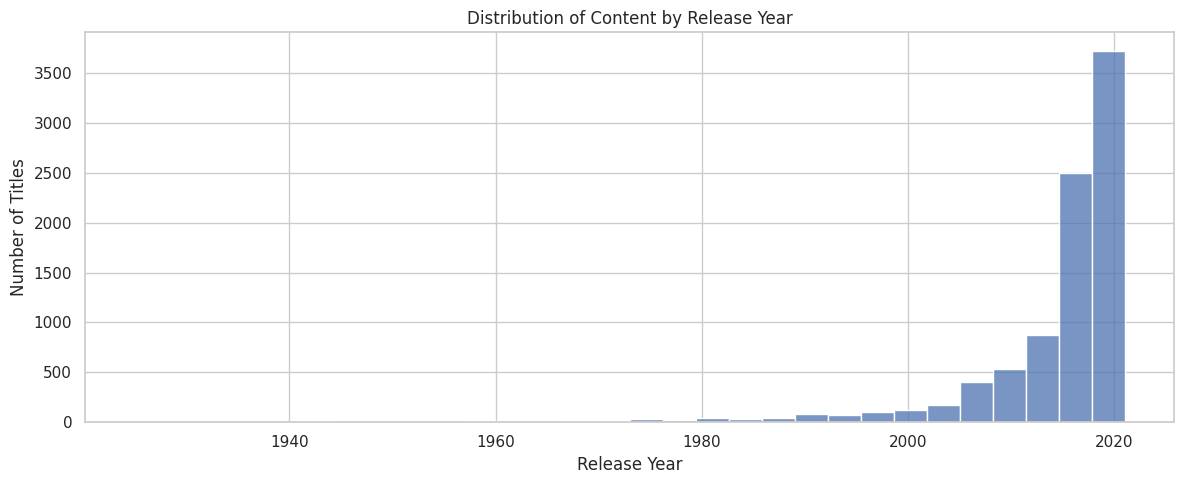

Share of catalogue released in the latest 10 release years: 80.54%


In [ ]:
plt.figure(figsize=(12, 5))
sns.histplot(df["release_year"], bins=30)
plt.title("Distribution of Content by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

recent_10_years = df[df["release_year"] >= df["release_year"].max() - 9]
recent_share = len(recent_10_years) / len(df) * 100
print(f"Share of catalogue released in the latest 10 release years: {recent_share:.2f}%")

### Insight

**80.54%** of the catalogue falls within the latest 10 release years, showing that Netflix's catalogue is strongly concentrated toward newer content. This reinforces the importance of maintaining a continuous pipeline of recent content.


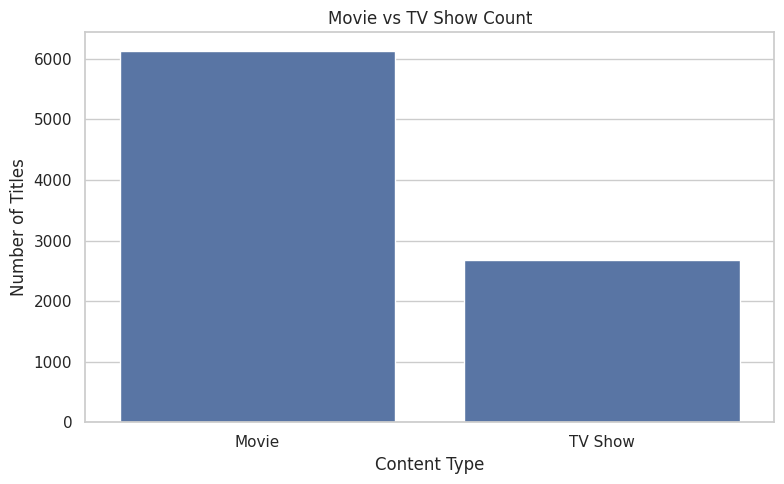

Movies: 6131 (69.62%)
TV Shows: 2676 (30.38%)
Movies exceed TV Shows by 3455 titles


In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="type")
plt.title("Movie vs TV Show Count")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

print(f"Movies: {movie_count} ({movie_share:.2f}%)")
print(f"TV Shows: {tv_count} ({tv_share:.2f}%)")
print(f"Movies exceed TV Shows by {movie_count - tv_count} titles")

### Insight

Movies exceed TV Shows by **3,455 titles**, confirming that Movies remain the dominant accumulated format. A substantial increase in TV additions would therefore be required to materially change the overall catalogue balance.

## 4.3 Bivariate Analysis

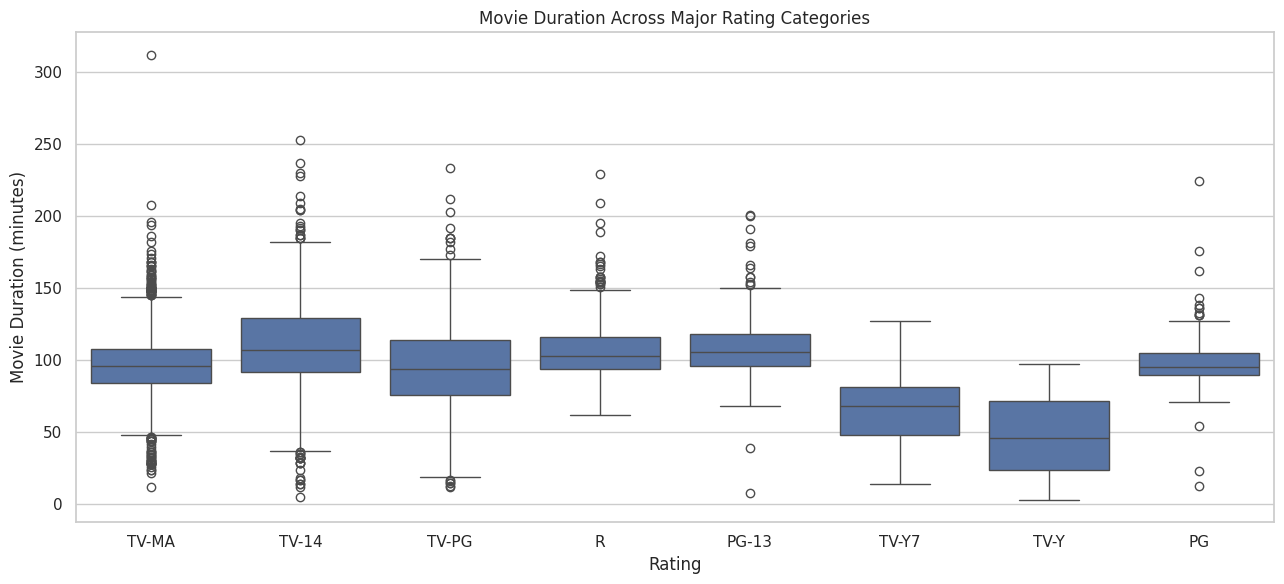

Highest median duration rating: TV-14 (107.00 minutes)
Lowest median duration rating: TV-Y (46.00 minutes)
Median duration difference: 61.00 minutes


In [ ]:
top_ratings = df["rating"].value_counts().head(8).index.tolist()
movie_rating_duration = df[
    df["type"].eq("Movie") &
    df["rating"].isin(top_ratings) &
    df["movie_duration"].notna()
].copy()

plt.figure(figsize=(13, 6))
sns.boxplot(data=movie_rating_duration, x="rating", y="movie_duration", order=top_ratings)
plt.title("Movie Duration Across Major Rating Categories")
plt.xlabel("Rating")
plt.ylabel("Movie Duration (minutes)")
plt.tight_layout()
plt.show()

rating_medians = movie_rating_duration.groupby("rating", observed=True)["movie_duration"].median().sort_values(ascending=False)
highest_median_rating = rating_medians.index[0]
highest_median_duration = rating_medians.iloc[0]
lowest_median_rating = rating_medians.index[-1]
lowest_median_duration = rating_medians.iloc[-1]

print(f"Highest median duration rating: {highest_median_rating} ({highest_median_duration:.2f} minutes)")
print(f"Lowest median duration rating: {lowest_median_rating} ({lowest_median_duration:.2f} minutes)")
print(f"Median duration difference: {highest_median_duration - lowest_median_duration:.2f} minutes")

### Insight

The **highest median** Movie duration is for TV-14 titles at **107 minutes**, while the **lowest** is for TV-Y titles at **46 minutes**, **a difference of 61 minutes**. This shows that typical Movie runtime varies substantially across rating categories, although rating alone should not determine runtime decisions.


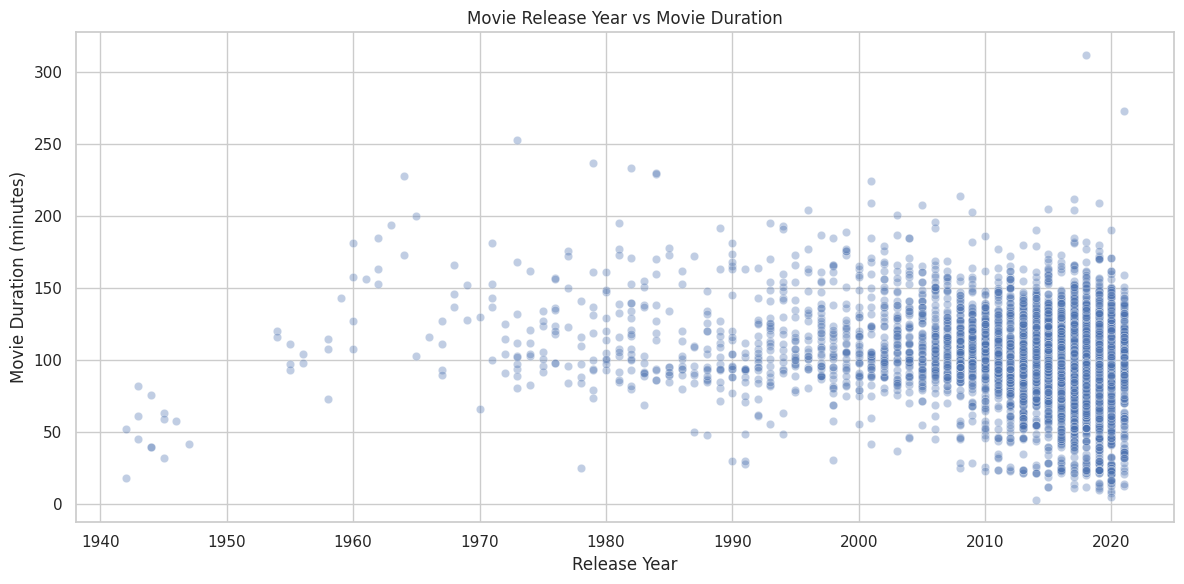

Pearson correlation: -0.206


In [ ]:
scatter_data = df[df["type"].eq("Movie") & df["movie_duration"].notna()].copy()
plt.figure(figsize=(12, 6))
sns.scatterplot(data=scatter_data, x="release_year", y="movie_duration", alpha=0.35)
plt.title("Movie Release Year vs Movie Duration")
plt.xlabel("Release Year")
plt.ylabel("Movie Duration (minutes)")
plt.tight_layout()
plt.show()

correlation = scatter_data["release_year"].corr(scatter_data["movie_duration"])
print(f"Pearson correlation: {correlation:.3f}")

### Insight

The Pearson correlation is approximately **−0.206**, indicating a **weak negative relationship** between release year and Movie duration. Newer Movies tend to be slightly shorter, but the relationship is too weak for release year to be a strong predictor of runtime.

In [ ]:
correlation_table = pd.DataFrame({
    "Variable 1": ["Release Year", "Release Year"],
    "Variable 2": ["Movie Duration", "TV Seasons"],
    "Pearson Correlation": [
        df.loc[df["movie_duration"].notna(), "release_year"].corr(df.loc[df["movie_duration"].notna(), "movie_duration"]),
        df.loc[df["tv_seasons"].notna(), "release_year"].corr(df.loc[df["tv_seasons"].notna(), "tv_seasons"])
    ]
})
correlation_table["Strength"] = correlation_table["Pearson Correlation"].abs().apply(
    lambda x: "Very weak" if x < 0.2 else "Weak" if x < 0.4 else "Moderate" if x < 0.7 else "Strong"
)
display(correlation_table)

,Variable 1,Variable 2,Pearson Correlation,Strength
0,Release Year,Movie Duration,-0.206285,Weak
1,Release Year,TV Seasons,-0.090194,Very weak


### Insight

The correlation table confirms that release year has limited linear explanatory power for Movie duration and TV Show season count. Content planning should therefore use additional characteristics such as genre, rating and format rather than relying on release year alone.

# 5. Missing Value & Outlier Analysis

Missing values and unusual numerical observations are evaluated to understand their potential effect on business conclusions. Statistical outliers are not automatically removed because extreme runtimes may represent legitimate content.

In [ ]:
missing_analysis = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing %": (df.isnull().sum() / len(df) * 100).round(2)
}).sort_values("Missing Count", ascending=False)
display(missing_analysis[missing_analysis["Missing Count"] > 0])

,Missing Count,Missing %
tv_seasons,6131,69.62
movie_duration,2679,30.42
director,2634,29.91
country,831,9.44
cast,825,9.37
month_added,98,1.11
month_name,98,1.11
month_num,98,1.11
year_added,98,1.11
date_added,98,1.11


### Insight

The largest metadata gaps are in creator and country fields. Incomplete metadata can cause markets or creators to appear less represented than they actually are, so geographic and creator conclusions should be interpreted with this coverage limitation in mind.

In [ ]:
duration_series = df["movie_duration"].dropna()
Q1 = duration_series.quantile(0.25)
Q3 = duration_series.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outlier_mask = (duration_series < lower_bound) | (duration_series > upper_bound)
outlier_count = int(outlier_mask.sum())
outlier_pct = outlier_count / len(duration_series) * 100

print(f"Q1: {Q1:.2f} minutes")
print(f"Q3: {Q3:.2f} minutes")
print(f"IQR: {IQR:.2f} minutes")
print(f"Lower bound: {lower_bound:.2f} minutes")
print(f"Upper bound: {upper_bound:.2f} minutes")
print(f"Potential statistical outliers: {outlier_count} ({outlier_pct:.2f}%)")

Q1: 87.00 minutes
Q3: 114.00 minutes
IQR: 27.00 minutes
Lower bound: 46.50 minutes
Upper bound: 154.50 minutes
Potential statistical outliers: 450 (7.34%)


### Insight

The 1.5×IQR rule identifies the number and percentage of potential statistical outliers printed above. These records should not automatically be removed because unusually long Movies can be legitimate. The appropriate business action is to validate unusual records before changing the data.

# 6. Insights Based on Non-Graphical and Visual Analysis

## 6.1 Range of Key Attributes

- The dataset contains **8,807** titles.
- Movies represent **6,131** titles, while TV Shows represent **2,676**.
- Movie duration ranges widely, with a median of 98 minutes and the middle 50% of Movies falling between 87 and 114 minutes.
- Release years span a broad historical period, with much stronger representation in recent years.

## 6.2 Distribution and Relationships

- The catalogue is Movie-heavy, at approximately **69.6%**, compared with **30.4%** TV Shows.
- Movie representation is concentrated toward newer release years.
- Movie duration has a central concentration with some unusually short/long observations.
- The relationship between release year and movie duration is weakly negative **(Pearson r ≈ −0.21)**, indicating that newer movies tend to be somewhat shorter, but the relationship is not strong.

## 6.3 Business Meaning of Major Visual Findings

### Movie Release Trend
Movie representation is concentrated more heavily in recent release years. The number of represented Movies increased from 103 in the first five available years to 2,961 in the last five years, showing a much stronger presence of newer Movie content in the catalogue. This supports maintaining a continuous pipeline of newer Movie content.

### Movies vs TV Shows
Movies account for 69.6% of the catalogue compared with 30.4% for TV Shows, a difference of 3,455 titles. Movies therefore remain the dominant accumulated format.

### TV Show Addition Timing
July recorded the highest historical TV Show addition volume, with 254 TV Shows (9.85% of dated TV Show additions). It can therefore be used as a historical planning benchmark, but this does not establish that July produces better viewer or financial outcomes.

### Actors and Directors
A smaller group of actors and directors appears repeatedly across the catalogue, with different levels of Movie and TV Show representation. Their catalogue representation can be used as a starting point for further evaluation using audience performance and production-cost data.

### Country Analysis
Movie and TV Show representation varies across major countries, showing that Netflix's catalogue mix is not uniform across markets. Country-level genre differences also indicate areas that can be evaluated against local demand.

### Rating and Movie Duration
Median Movie duration differs across major rating categories, showing that typical runtime varies by audience-rating group. However, the overlap between groups means rating should not be the sole basis for runtime decisions.

### Release Year and Movie Duration
The Pearson correlation of approximately **−0.206** indicates a weak negative relationship. Release year alone therefore provides limited information about Movie runtime.

# 7. Business Insights

1. **Movies remain Netflix's core catalogue format.** With 6,131 Movies versus 2,676 TV Shows, Movies represent approximately 69.6% of the catalogue.

2. **The catalogue has strong recent-content representation.** The first five available release years contain only 103 Movies, compared with 2,961 Movies in the last five available years, showing much stronger representation of newer Movie content.

3. **Recent TV strategy should be measured through additions.** TV Shows increased from 4.76% of additions in the first five available years to 29.24% in the last five years, a rise of 24.48 percentage points. This provides stronger evidence of changing TV Show focus than the accumulated catalogue mix alone.

4. **TV Show additions have a historical monthly pattern.** July recorded the highest historical TV Show addition volume, with 254 TV Shows (9.85% of dated TV Show additions). This provides a useful historical planning benchmark, but does not prove that July produces better viewer or financial outcomes.

5. **Country content structures differ.** Major markets have different Movie/TV proportions, supporting country-specific content planning.

6. **Creator representation differs by format.** Anupam Kher has 43 catalogue titles, mainly Movies, while Takahiro Sakurai has the highest TV Show representation with 25 titles. The most represented director, Rajiv Chilaka, has 22 Movie titles and no TV Shows.

7. **Genre coverage differs by country.** The United States has the largest catalogue representation among the top countries, with 3,690 associated titles, while South Korea has the highest TV Show share at 73.59%. This shows that the Movie/TV mix differs considerably by market.

8. **Movie runtimes vary materially.** The median Movie duration is 98 minutes, with the middle 50% of Movies ranging from 87 to 114 minutes. The analysis also identifies 450 potential statistical outliers (7.34%) under the 1.5×IQR rule, showing that runtime is not uniform across the catalogue.

9. **Release year has weak explanatory power for Movie runtime.** The approximately −0.206 correlation means newer release year is only weakly associated with shorter Movies.

10. **Catalogue size is not the same as business success.** This dataset measures content representation and availability, but cannot establish viewing demand, retention, profitability or return on content investment.

# 8. Recommendations

1. **Keep Movies as a core portfolio segment while selectively expanding TV Shows.** Movies currently represent approximately 69.6% of the catalogue, so TV expansion should be measured against the existing portfolio.

2. **Track the Movie-to-TV mix every year.** Annual addition share provides a clearer signal of strategic direction than the accumulated catalogue.

3. **Use the strongest historical TV addition month as a planning benchmark.** July had the highest historical addition volume with 254 TV Shows (9.85% of dated TV Show additions). Future launch planning should test whether this timing also improves viewer engagement.

4. **Build country-specific content plans.** Differences in Movie/TV mix and genre concentration indicate that markets should not all receive the same content strategy.

5. **Prioritise creator partnerships based on both catalogue representation and performance.** Anupam Kher has 43 catalogue titles, while Takahiro Sakurai has 25 TV Show titles. These high-representation creators can be shortlisted for further evaluation, while future investment decisions should also consider viewing, retention and production-cost results.

6. **Tailor genre planning to each market.** The country vs genre analysis shows different levels of catalogue representation across markets. Netflix should identify underrepresented genres in each country and test them against local viewing demand before increasing investment.

7. **Strengthen country, cast and director metadata coverage.** Missing information is concentrated in these fields, with director data missing for roughly 30% of records. Improving these fields will make country and creator comparisons more reliable.

8. **Review unusually long Movie durations before making data corrections.** The 1.5×IQR rule identifies 450 potential statistical outliers (7.34%), with an upper boundary of 154.5 minutes. These records should be checked individually because some may represent legitimate long-form Movies.

9. **Monitor whether the growing TV Show share delivers better customer outcomes.** TV Shows increased from 4.76% of additions in the first 5 available years to 29.24% in the last 5 years, a 24.48 percentage-point increase. Netflix should track whether this expansion improves viewing, completion and retention.

10. **Use customer and financial performance data before making major content investment decisions.** Catalogue representation alone cannot show whether content is successful, so future decisions should combine catalogue trends with viewing, retention, revenue and content-cost measures.

# 9. Executive Summary

## 10-Point Management Summary

1. **Movies remain the dominant format**, representing approximately 69.6% of Netflix's catalogue versus 30.4% TV Shows.

2. **Newer release years have strong catalogue representation**, highlighting the importance of maintaining content freshness.

3. **TV strategy should be evaluated using annual additions**, because the accumulated catalogue reflects many years of historical content.

4. **TV Show additions show historical monthly seasonality**, which can be used as a planning benchmark but not as proof of the best-performing launch period.

5. **Country content mixes differ**, supporting market-specific rather than one-size-fits-all content planning.

6. **Creator representation is concentrated**, with certain actors and directors appearing repeatedly in the catalogue.

7. **Creator frequency is not equivalent to popularity**, because the dataset contains no audience or revenue measures.

8. **Movie duration varies substantially**, and statistical outliers should be validated rather than automatically removed.

9. **The approximately −0.206 correlation between release year and Movie duration is weak**, so release year alone is not a reliable runtime predictor.

10. **The most important next step is connecting catalogue data with customer behaviour and financial outcomes**, including viewing, completion, retention, revenue and content cost.